# Onboarding 01 - Data preparation

This notebook introduces HEST metadata and the breast spatial-transcriptomics cohort, previews one paired H&E patch and expression profile, then prepares aligned files for modeling. The catalog has one row per tissue section; sections belong to patients and contain many measured spots. Expression is stored as a sparse spot-by-gene matrix.

The test run selects three patients; set `N_PATIENTS = None` for all 23. Set the `DATA_DIR_NAME` string to the shared Drive location, a local directory, or a Google Drive Desktop mirrored directory. Keep the same root in Notebooks 02-03. Detailed concept notes for the libraries we are using: [study materials](../../docs/study_materials.md).

**Creates:** raw patches/expression, `spot_table.csv`, `samples.csv`, `genes.txt`, and sparse log1p expression matrices.

In [ ]:
%pip install -q huggingface_hub anndata h5py scipy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import anndata
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download, login

d:\my-apps\anaconda3\envs\hist2st\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Storage:** Mount Drive in Colab only if the data root is on Drive. Local and Drive Desktop paths work by setting `DATA_DIR_NAME` in Settings.

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Colab runtime: Drive mounted.')
except ImportError:
    print('Local runtime: no Drive mount needed.')

Local runtime: no Drive mount needed.


## Settings

Everything you might change is in this cell. Nothing below it should need editing.

- `TEAM_FOLDER`: the shared team folder on Drive
- `DATA_DIR_NAME` (string): where this notebook saves its data, inside the team folder
- `N_PATIENTS`: how many patients to use. `3` for the test run, `None` for all 23
- `STUDY_TITLE_START`: which study to use (the start of its `dataset_title` in the HEST table)

In [ ]:
# Examples: '/content/drive/MyDrive/BDD_BJMJ/HEST_breast_ST', './data/HEST_breast_ST', or your Drive Desktop folder.
DATA_DIR_NAME = '../data/'  # Edit this string for Drive, local storage, or Drive Desktop.
METADATA_FILE = 'HEST_v1_3_0.csv'
ORGAN, SPECIES, TECHNOLOGY = 'Breast', 'Homo sapiens', 'Spatial Transcriptomics'
STUDY_TITLE_START = 'Integrating spatial gene expression and breast tumour morphology'
N_PATIENTS = 3  # Set to None for all 23 patients.

In [15]:
DATA_DIR_PATH = Path(DATA_DIR_NAME).expanduser().resolve()
RAW_DIR = DATA_DIR_PATH / 'raw'
EXPRESSION_DIR = DATA_DIR_PATH / 'expression'
RAW_DIR.mkdir(parents=True, exist_ok=True)
EXPRESSION_DIR.mkdir(parents=True, exist_ok=True)
print('Saving to:', DATA_DIR_PATH)

Saving to: C:\Users\Siyu_\Documents\JHU_Files\courses\697_BDD\Hist2ST\data


**Hugging Face login:** paste your token into the box that appears. Never write it in the code or upload it to GitHub.

In [16]:
login()

## Step 1. Choose the sections

The HEST table has one row per section. We keep the human breast sections from our study, and drop any without a patient ID (this study has none missing, but other studies do).

In this study the patient IDs look like `BC23209`, and each patient has 2–3 sections. Several sections from one patient are why the patient split matters: they must all land on the same side of the split.

In [18]:
metadata_path = hf_hub_download(
    repo_id="MahmoodLab/hest",
    repo_type="dataset",
    filename=METADATA_FILE,
    local_dir=RAW_DIR,
)
metadata = pd.read_csv(metadata_path, encoding="utf-8-sig")
print("All samples in HEST:", len(metadata))

is_organ = metadata["organ"] == ORGAN
is_species = metadata["species"] == SPECIES
is_technology = metadata["st_technology"] == TECHNOLOGY
is_study = metadata["dataset_title"].str.startswith(STUDY_TITLE_START)
has_patient = metadata["patient"].notna()

study_samples = metadata[is_organ & is_species & is_technology & is_study & has_patient].copy()

print("Sections in our study:", len(study_samples))
print("Patients in our study:", study_samples["patient"].nunique())
display(metadata.head())

All samples in HEST: 1276
Sections in our study: 68
Patients in our study: 23


,dataset_title,id,image_filename,organ,disease_state,oncotree_code,species,patient,st_technology,data_publication_date,...,treatment_comment,pixel_size_um_embedded,pixel_size_um_estimated,magnification,fullres_px_width,fullres_px_height,tissue,disease_comment,subseries,hest_version_added
0,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX202,TENX202.tif,Breast,Cancer,IDC,Homo sapiens,Patient 4,Xenium,2025-12-11,...,NaN,0.273809,0.273968,NaN,21607,30322,Breast,"DCIS, T4a N2a, G3, HER2-1+","Section 4, bottom",v1_3_0
1,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX201,TENX201.tif,Breast,Cancer,IDC,Homo sapiens,Patient 4,Xenium,2025-12-11,...,NaN,0.273810,0.274040,NaN,22892,39456,Breast,"IDC, T2 N0 MX, Not provided, ER+/PR+/HER2-2+","Section 4, middle",v1_3_0
2,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX200,TENX200.tif,Breast,Cancer,IDC,Homo sapiens,Patient 4,Xenium,2025-12-11,...,NaN,0.273813,0.273959,NaN,26717,46370,Breast,"IDC, Tis NX MX, G3, ER+/PR+/HER2-1+","Section 4, top",v1_3_0
3,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX199,TENX199.tif,Breast,Cancer,IDC,Homo sapiens,Patient 3,Xenium,2025-12-11,...,NaN,0.273808,0.274062,NaN,14853,31607,Breast,"DCIS, TX NX M0, G2, ER-/PR-/HER2-2+","Section 3, bottom",v1_3_0
4,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX198,TENX198.tif,Breast,Cancer,IDC,Homo sapiens,Patient 3,Xenium,2025-12-11,...,NaN,0.273813,0.274110,NaN,32654,35502,Breast,"DCIS, T4b N3a M1, G2, ER+/PR+/HER2-2+","Section 3, middle",v1_3_0


### Inspect the metadata catalog
Each row is a section/sample. These summaries show the shape of the catalog, its columns, available technologies, and missing patient IDs.

In [19]:
print('Metadata shape:', metadata.shape)
print('Columns:', metadata.columns.tolist())
print('Missing patient IDs:', int(metadata['patient'].isna().sum()))
human = metadata[metadata['species'].eq('Homo sapiens')]
display(human['organ'].value_counts().head(10).rename('sections').to_frame())
display(human['st_technology'].value_counts().rename('sections').to_frame())


Metadata shape: (1276, 28)
Columns: ['dataset_title', 'id', 'image_filename', 'organ', 'disease_state', 'oncotree_code', 'species', 'patient', 'st_technology', 'data_publication_date', 'license', 'study_link', 'download_page_link1', 'inter_spot_dist', 'spot_diameter', 'spots_under_tissue', 'preservation_method', 'nb_genes', 'treatment_comment', 'pixel_size_um_embedded', 'pixel_size_um_estimated', 'magnification', 'fullres_px_width', 'fullres_px_height', 'tissue', 'disease_comment', 'subseries', 'hest_version_added']
Missing patient IDs: 870


,sections
organ,
Breast,140
Bowel,84
Skin,80
Lung,70
Kidney,65
Heart,62
Prostate,61
Brain,43
Uterus,17


,sections
st_technology,
Visium,421
Spatial Transcriptomics,163
Xenium,73
Visium HD,21
Xenium 5k,7
Visium HD 3',4


In [20]:
sections_per_patient = study_samples.groupby("patient")["id"].apply(list)
print(sections_per_patient.to_string())

patient
BC23209       [SPA62, SPA61, SPA60]
BC23268       [SPA89, SPA88, SPA87]
BC23269       [SPA86, SPA85, SPA84]
BC23270       [SPA77, SPA76, SPA75]
BC23272       [SPA83, SPA82, SPA81]
BC23277       [SPA74, SPA73, SPA72]
BC23287    [SPA118, SPA117, SPA116]
BC23288       [SPA59, SPA58, SPA57]
BC23377       [SPA56, SPA55, SPA54]
BC23450    [SPA115, SPA114, SPA113]
BC23506       [SPA71, SPA70, SPA69]
BC23508       [SPA68, SPA67, SPA66]
BC23567    [SPA104, SPA103, SPA102]
BC23803       [SPA53, SPA52, SPA51]
BC23810     [SPA101, SPA100, SPA99]
BC23895       [SPA65, SPA64, SPA63]
BC23901            [SPA112, SPA111]
BC23903       [SPA98, SPA97, SPA96]
BC23944    [SPA110, SPA109, SPA108]
BC24044       [SPA95, SPA94, SPA93]
BC24105       [SPA92, SPA91, SPA90]
BC24220    [SPA107, SPA106, SPA105]
BC24223       [SPA80, SPA79, SPA78]


For the test run we keep the first `N_PATIENTS` patients (sorted by ID, so everyone gets the same ones) with **all** of their sections.

In [21]:
all_patients = sorted(study_samples["patient"].unique())

if N_PATIENTS is None:
    chosen_patients = all_patients
else:
    chosen_patients = all_patients[:N_PATIENTS]

samples = study_samples[study_samples["patient"].isin(chosen_patients)]
samples = samples.sort_values(["patient", "id"]).reset_index(drop=True)
sample_ids = samples["id"].tolist()

print("Patients used:", len(chosen_patients), chosen_patients)
print("Sections used:", len(sample_ids), sample_ids)
print("Spots expected (from metadata):", samples["spots_under_tissue"].sum())

Patients used: 3 ['BC23209', 'BC23268', 'BC23269']
Sections used: 9 ['SPA60', 'SPA61', 'SPA62', 'SPA87', 'SPA88', 'SPA89', 'SPA84', 'SPA85', 'SPA86']
Spots expected (from metadata): 3670


## Step 2. Download patches and expression

For each section we download two files:
- `patches/<id>.h5`: one 224×224 H&E patch per spot, plus its barcode and coordinates
- `st/<id>.h5ad`: the expression table, spots × genes, with each spot's barcode

Files that are already downloaded are skipped, so if the run stops (or Colab disconnects) you can just run this cell again.

In [22]:
for sample_id in sample_ids:
    patches_path = RAW_DIR / "patches" / f"{sample_id}.h5"
    st_path = RAW_DIR / "st" / f"{sample_id}.h5ad"

    if patches_path.exists() and st_path.exists():
        print(sample_id, "already downloaded")
        continue

    hf_hub_download(repo_id="MahmoodLab/hest", repo_type="dataset",
                    filename=f"patches/{sample_id}.h5", local_dir=RAW_DIR)
    hf_hub_download(repo_id="MahmoodLab/hest", repo_type="dataset",
                    filename=f"st/{sample_id}.h5ad", local_dir=RAW_DIR)
    print(sample_id, "downloaded")

SPA60 downloaded
SPA61 downloaded
SPA62 downloaded
SPA87 downloaded
SPA88 downloaded
SPA89 downloaded
SPA84 downloaded
SPA85 downloaded
SPA86 downloaded


In [23]:
total_bytes = 0
for sample_id in sample_ids:
    total_bytes += Path(RAW_DIR / "patches" / f"{sample_id}.h5").stat().st_size
    total_bytes += Path(RAW_DIR / "st" / f"{sample_id}.h5ad").stat().st_size

size_per_section = total_bytes / len(sample_ids)
print(f"Downloaded: {total_bytes / 1e9:.2f} GB for {len(sample_ids)} sections")
print(f"Estimate for all {len(study_samples)} sections: {size_per_section * len(study_samples) / 1e9:.1f} GB")

Downloaded: 1.13 GB for 9 sections
Estimate for all 68 sections: 8.5 GB


## Step 3. Match patches to expression by barcode

The barcode is the spot's ID. A patch and an expression row belong to the same spot only if their barcodes match, so we never line them up by position.

For each section we keep the spots that have **both** a patch and an expression row. We also record:
- `patch_index`: where the spot's patch sits in the `.h5` file (Notebook 2 reads patches in this order)
- `row_in_sample`: the spot's row in this section's saved expression file

In [24]:
def barcode_to_text(barcode):
    if hasattr(barcode, "ravel"):
        barcode = barcode.ravel()[0]
    if isinstance(barcode, bytes):
        barcode = barcode.decode("utf-8")
    return str(barcode)


def read_patch_barcodes(patches_path):
    with h5py.File(patches_path, "r") as f:
        raw_barcodes = f["barcode"][:]
        coords = f["coords"][:]
    barcodes = np.array([barcode_to_text(b) for b in raw_barcodes])
    return barcodes, coords

In [25]:
spot_tables = []
gene_lists = []

for sample_id in sample_ids:
    patches_path = RAW_DIR / "patches" / f"{sample_id}.h5"
    st_path = RAW_DIR / "st" / f"{sample_id}.h5ad"

    patch_barcodes, coords = read_patch_barcodes(patches_path)

    adata = anndata.read_h5ad(st_path, backed="r")
    expression_barcodes = set(adata.obs_names)
    gene_names = pd.Index(adata.var_names)
    gene_lists.append(list(anndata.utils.make_index_unique(gene_names)))
    adata.file.close()

    keep = np.array([b in expression_barcodes for b in patch_barcodes])
    patient = samples.loc[samples["id"] == sample_id, "patient"].iloc[0]

    table = pd.DataFrame({
        "sample_id": sample_id,
        "patient": patient,
        "barcode": patch_barcodes[keep],
        "x": coords[keep, 0],
        "y": coords[keep, 1],
        "patch_index": np.where(keep)[0],
    })
    table["row_in_sample"] = np.arange(len(table))
    spot_tables.append(table)

    print(f"{sample_id}: {len(patch_barcodes)} patches, {keep.sum()} matched to expression")

spot_table = pd.concat(spot_tables, ignore_index=True)
print()
print("Total spots:", len(spot_table))

SPA60: 331 patches, 331 matched to expression
SPA61: 318 patches, 318 matched to expression
SPA62: 293 patches, 293 matched to expression
SPA87: 489 patches, 489 matched to expression
SPA88: 498 patches, 498 matched to expression
SPA89: 435 patches, 435 matched to expression
SPA84: 431 patches, 431 matched to expression
SPA85: 435 patches, 435 matched to expression
SPA86: 433 patches, 433 matched to expression

Total spots: 3663


### Preview a paired patch and expression profile
The image patch and expression row are joined by barcode. The plot demonstrates what "paired data" means: image and gene values describe the same location.

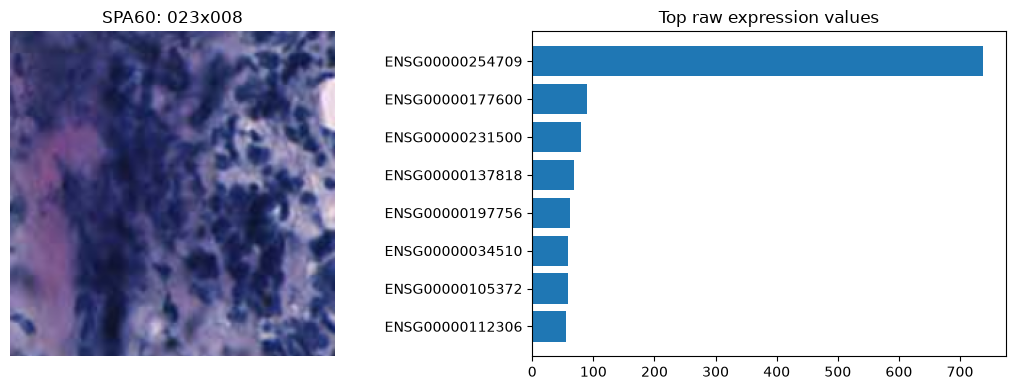

In [26]:
sample_id = sample_ids[0]
spot = spot_table[spot_table['sample_id'].eq(sample_id)].iloc[0]
with h5py.File(RAW_DIR / 'patches' / f'{sample_id}.h5', 'r') as f:
    patch_image = f['img'][int(spot.patch_index)]
adata_preview = anndata.read_h5ad(RAW_DIR / 'st' / f'{sample_id}.h5ad')
adata_preview.var_names_make_unique()
row = int(adata_preview.obs_names.get_loc(spot.barcode))
values = adata_preview.X[row]
values = values.toarray().ravel() if scipy.sparse.issparse(values) else np.asarray(values).ravel()
top = np.argsort(values)[-8:][::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(patch_image); axes[0].set_title(f'{sample_id}: {spot.barcode}'); axes[0].axis('off')
axes[1].barh(adata_preview.var_names[top][::-1], values[top][::-1]); axes[1].set_title('Top raw expression values')
plt.tight_layout(); plt.show()
adata_preview.file.close()


## Step 4. Keep the genes every section measured

Different sections can list slightly different genes. Notebook 3 needs the same columns for every spot, so we keep only genes present in **all** chosen sections.

This is not gene selection: it doesn't look at expression values, only at which genes exist, so it can be done before the split. Choosing the top 50 genes by variance happens in Notebook 3, on training spots only.

In [27]:
shared_genes = set(gene_lists[0])
for genes in gene_lists[1:]:
    shared_genes = shared_genes & set(genes)

shared_genes = sorted(shared_genes)

print("Genes per section:", [len(g) for g in gene_lists])
print("Genes shared by all sections:", len(shared_genes))

Genes per section: [18298, 18356, 16859, 17417, 17467, 17546, 17576, 18371, 17779]
Genes shared by all sections: 13875


## Step 5. Save log1p expression for each section

For each section we:
1. reorder its expression rows to match the spot table (by barcode)
2. keep the shared genes, in the same order for every section
3. apply log1p, so ln(1 + count): this evens out very large counts and keeps zeros at 0
4. save it as a sparse matrix (most counts are 0, so this keeps the files small)

log1p is applied to each number on its own and learns nothing from other spots, so doing it here can't leak test information.

In [28]:
for sample_id in sample_ids:
    st_path = RAW_DIR / "st" / f"{sample_id}.h5ad"
    adata = anndata.read_h5ad(st_path)
    adata.var_names_make_unique()

    sample_spots = spot_table[spot_table["sample_id"] == sample_id]
    adata = adata[sample_spots["barcode"].values, shared_genes]

    counts = scipy.sparse.csr_matrix(adata.X, dtype=np.float32)
    log_expression = counts.log1p()

    scipy.sparse.save_npz(EXPRESSION_DIR / f"{sample_id}.npz", log_expression)
    print(f"{sample_id}: saved {log_expression.shape[0]} spots x {log_expression.shape[1]} genes")

SPA60: saved 331 spots x 13875 genes
SPA61: saved 318 spots x 13875 genes
SPA62: saved 293 spots x 13875 genes
SPA87: saved 489 spots x 13875 genes
SPA88: saved 498 spots x 13875 genes
SPA89: saved 435 spots x 13875 genes
SPA84: saved 431 spots x 13875 genes
SPA85: saved 435 spots x 13875 genes
SPA86: saved 433 spots x 13875 genes


### Summarize average expression
The saved values are `log1p(count)`. The chart shows average log expression per shared gene and average expression per spot; these are descriptive summaries, not gene selection.

Matrix (spots x shared genes): (3663, 13875)
Average log1p value across all entries: 0.11723914742469788


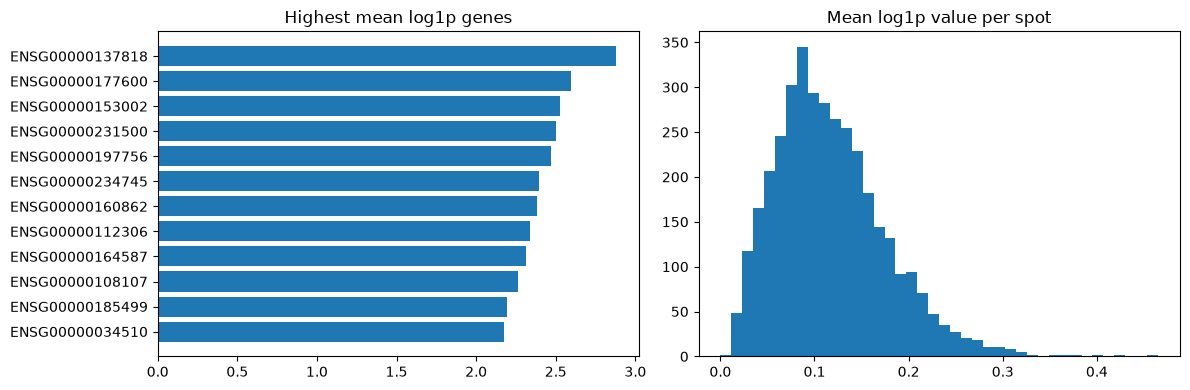

In [29]:
combined_expression = scipy.sparse.vstack([scipy.sparse.load_npz(EXPRESSION_DIR / f'{sid}.npz') for sid in sample_ids]).tocsr()
mean_gene = np.asarray(combined_expression.mean(axis=0)).ravel()
mean_spot = np.asarray(combined_expression.mean(axis=1)).ravel()
print('Matrix (spots x shared genes):', combined_expression.shape)
print('Average log1p value across all entries:', float(combined_expression.mean()))
idx = np.argsort(mean_gene)[-12:][::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(np.asarray(shared_genes)[idx][::-1], mean_gene[idx][::-1]); axes[0].set_title('Highest mean log1p genes')
axes[1].hist(mean_spot, bins=40); axes[1].set_title('Mean log1p value per spot')
plt.tight_layout(); plt.show()


In [30]:
spot_table.to_csv(DATA_DIR_PATH / "spot_table.csv", index=False)

with (DATA_DIR_PATH / "genes.txt").open("w") as f:
    for gene in shared_genes:
        f.write(gene + "\n")

samples.to_csv(DATA_DIR_PATH / "samples.csv", index=False)

print("Saved spot_table.csv, genes.txt and samples.csv to", DATA_DIR_PATH)

Saved spot_table.csv, genes.txt and samples.csv to C:\Users\Siyu_\Documents\JHU_Files\courses\697_BDD\Hist2ST\data


## Step 6. Check the result

Quick checks before moving on:
- every section has spots, and the counts match the metadata roughly
- each patient's sections are listed together
- one section plotted on the slide, coloured by total expression, should look like tissue (not random noise). If it looks random, the barcode matching went wrong.

In [31]:
summary = spot_table.groupby(["patient", "sample_id"]).size().rename("spots").reset_index()
summary = summary.merge(samples[["id", "spots_under_tissue"]], left_on="sample_id", right_on="id")
summary = summary.drop(columns="id").rename(columns={"spots_under_tissue": "spots_in_metadata"})
print(summary.to_string(index=False))
print()
print("Patients:", spot_table["patient"].nunique())
print("Sections:", spot_table["sample_id"].nunique())
print("Spots:", len(spot_table))
print("Genes:", len(shared_genes))

patient sample_id  spots  spots_in_metadata
BC23209     SPA60    331                331
BC23209     SPA61    318                318
BC23209     SPA62    293                294
BC23268     SPA87    489                492
BC23268     SPA88    498                498
BC23268     SPA89    435                435
BC23269     SPA84    431                433
BC23269     SPA85    435                435
BC23269     SPA86    433                434

Patients: 3
Sections: 9
Spots: 3663
Genes: 13875


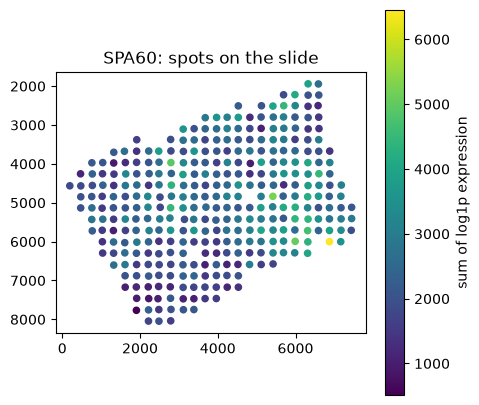

In [32]:
check_id = sample_ids[0]
check_spots = spot_table[spot_table["sample_id"] == check_id]
check_expression = scipy.sparse.load_npz(EXPRESSION_DIR / f"{check_id}.npz")
total_log_expression = np.asarray(check_expression.sum(axis=1)).ravel()

plt.figure(figsize=(5, 5))
plt.scatter(check_spots["x"], check_spots["y"], c=total_log_expression, s=20, cmap="viridis")
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.colorbar(label="sum of log1p expression")
plt.title(f"{check_id}: spots on the slide")
plt.show()

## Next

Run **Notebook 2 (Embedding)** in Colab on a **GPU** runtime. It reads `spot_table.csv` and the patch files, and saves one embedding file per section in the same spot order.